# DRep Reward Mechanism Description

#### This notebook analyzes a specific reward mechanism for Cardano Decentralized Representatives (DReps). The mechanism takes in input two parameters:

1. **Total Budget $B$.**
2. **Decentralization parameter $d$.**

## How it works:
1. **Threshold Eligibility**: The mechanism takes a decentralization parameter $d$ as an input and sets a threshold of $\frac{1}{d}$ of the total active voting power. A DRep must hold a fraction of the total voting power at or above this threshold to be eligible for rewards.
2. **Reward Distribution**: All DReps with voting power (including delegated stake) equal to or greater than the $\frac{1}{d}$ threshold receive an equal reward amount of $\frac{B}{d}$ each, where $B$ is the total allocated budget.


## Two alternative equivalent versions:
1. **Budget Version** Specify a fixed total budget $B$, and decentralization parameter $d$; Each qualified DRep receives a reward $P = B/d$.
2. **Reward Version** Specify a fixed reward $P$ for each qualifying DRep, and decentralization parameter $d$; The budget is equal to $B = P \times d$.

##Skewed Voting Power & Unconsumed Budget
Because voting power distribution is typically uneven, in general there will less than $d$ DReps who pass the threshold. Consequently, the actual consumed budget ($B_{\text{used}}$) is usually less than the total allocated budget $B$.


# Download Cardano DRep voting power from Koios
Run the cells in order. The last cell in this section tries to write `dreps.csv` and also prints the data so you can copy it into the chart page if writing is blocked.

In [ ]:
import json, time, urllib.request as u

A = "https://api.koios.rest/api/v1"
CHUNK = 20          # lower this to 10 if you get HTTP 413

def get(p, body=None):
    r = u.Request(
        A + p,
        data=json.dumps(body).encode() if body else None,
        headers={"accept": "application/json", "content-type": "application/json"},
    )
    return json.load(u.urlopen(r, timeout=60))

In [ ]:
# 1) all registered DRep ids, paged 1000 at a time
ids, off = [], 0
while True:
    page = get(f"/drep_list?registered=eq.true&select=drep_id&order=drep_id&limit=1000&offset={off}")
    ids += [d["drep_id"] for d in page]
    if len(page) < 1000:
        break
    off += 1000
print(len(ids), "registered DReps")

1051 registered DReps


In [ ]:
# 2) voting power in small batches
rows = []
for i in range(0, len(ids), CHUNK):
    rows += get("/drep_info", {"_drep_ids": ids[i:i + CHUNK]})
    if (i // CHUNK) % 10 == 0:
        print(f"{min(i + CHUNK, len(ids))} / {len(ids)}")
    time.sleep(0.1)  # be polite to the free API
print(len(rows), "DReps fetched")

20 / 1051
220 / 1051
420 / 1051
620 / 1051
820 / 1051
1020 / 1051
1051 DReps fetched


In [ ]:
# 3) names: fetch off-chain metadata only for active DReps with stake
active = [r for r in rows if r.get("active") is not False and int(r["amount"]) > 0]
ids2 = [r["drep_id"] for r in active]

def name_of(m):
    j = m.get("meta_json") or {}
    if not isinstance(j, dict):
        return ""
    body = j.get("body", j)
    n = body.get("givenName") if isinstance(body, dict) else None
    if isinstance(n, dict):            # some files use {"@value": "..."}
        n = n.get("@value")
    return n.strip() if isinstance(n, str) else ""

names = {}
for i in range(0, len(ids2), CHUNK):
    for m in get("/drep_metadata", {"_drep_ids": ids2[i:i + CHUNK]}):
        names[m["drep_id"]] = name_of(m)
    time.sleep(0.1)

def clean(s):
    return s.replace(",", " ").replace("\n", " ")

lines = [f'{clean(names.get(r["drep_id"]) or r["drep_id"])},{int(r["amount"]) / 1e6}'
         for r in active]
lines.sort(key=lambda l: -float(l.rsplit(",", 1)[1]))
csv_text = "\n".join(lines)
print(len(lines), "DReps,", sum(1 for r in active if names.get(r["drep_id"])), "with a name")

try:
    with open("dreps.csv", "w", encoding="utf-8") as f:
        f.write(csv_text)
    print("Wrote dreps.csv")
except OSError as e:
    print("Could not write file:", e)

print(csv_text[:1500])   # preview; print(csv_text) for everything

265 DReps, 223 with a name
Wrote dreps.csv
YUTA,482774913.502419
Yoroi W₳llet,389172035.87667
CryptoCrow,300151139.077436
Phil UPLC,229693530.86328
Eternl DRep Committee,228659851.815865
Everstake,215301642.726069
EMURGO,210721986.53419
Sebastien Guillemot セバ,170307176.35088
Cardano Foundation,150512643.984672
SASA_nagamaru_ながまる,130367068.939641
SIPO,120113673.434121
ranket,110745192.598273
JAZZ,96337966.597771
CardanoYoda (MANDA Pool),95125541.39666
Dumpling🥟,83313282.612473
Army of Spies,82824612.854874
Dave,78947715.360979
Dori,73323333.223137
Martin Lang,72274934.263542
Hermes Stakepool Germany (HRMS),65665073.849476
hix_coffeepool☕️,62564822.696994
FIMI,61524698.087173
AdaStat,48838002.468913
MUEN,44833757.935476
HISAI,43467304.248143
PoolTool,43249837.811641
Patrick_Tobler,41695478.578581
HOSKY,35145681.787475
Moonstake,34171810.529901
Aichi/Tokai_DRep,31994053.544917
NEDSCAVE.IO,30768094.387555
Goofycrisp,29052875.356456
Cerkoryn,29042318.848044
Socious,28126926.15147
TERA DRep,

In [ ]:
import csv

# Set parameter d
d = 1000

# Read DReps and their stakes from dreps.csv
dreps = []
total_stake = 0.0

with open("dreps.csv", "r") as f:
    reader = csv.reader(f)
    for row in reader:
        if len(row) == 2:
            drep_id = row[0]
            stake = float(row[1])
            dreps.append((drep_id, stake))
            total_stake += stake

# Calculate the threshold
threshold = total_stake / d

# Filter DReps meeting the threshold criteria
filtered_dreps = [(drep_id, stake) for drep_id, stake in dreps if stake >= threshold]

# Save the number of DReps passing the threshold in a variable d_passed
d_passed = len(filtered_dreps)

# Output results
print(f"Total Stake of active DReps: {total_stake:,.6f} ADA")
print(f"Threshold (1/{d} of total): {threshold:,.6f} ADA\n")
print(f"Found {d_passed} DReps with stake >= threshold:\n")

for drep_id, stake in sorted(filtered_dreps, key=lambda x: x[1], reverse=True):
    percentage = (stake / total_stake) * 100
    print(f"{drep_id}: {stake:,.6f} ADA ({percentage:.2f}%)")

Total Stake of active DReps: 4,638,395,775.032221 ADA
Threshold (1/1000 of total): 4,638,395.775032 ADA

Found 73 DReps with stake >= threshold:

YUTA: 482,774,913.502419 ADA (10.41%)
Yoroi W₳llet: 389,172,035.876670 ADA (8.39%)
CryptoCrow: 300,151,139.077436 ADA (6.47%)
Phil UPLC: 229,693,530.863280 ADA (4.95%)
Eternl DRep Committee: 228,659,851.815865 ADA (4.93%)
Everstake: 215,301,642.726069 ADA (4.64%)
EMURGO: 210,721,986.534190 ADA (4.54%)
Sebastien Guillemot セバ: 170,307,176.350880 ADA (3.67%)
Cardano Foundation: 150,512,643.984672 ADA (3.24%)
SASA_nagamaru_ながまる: 130,367,068.939641 ADA (2.81%)
SIPO: 120,113,673.434121 ADA (2.59%)
ranket: 110,745,192.598273 ADA (2.39%)
JAZZ: 96,337,966.597771 ADA (2.08%)
CardanoYoda (MANDA Pool): 95,125,541.396660 ADA (2.05%)
Dumpling🥟: 83,313,282.612473 ADA (1.80%)
Army of Spies: 82,824,612.854874 ADA (1.79%)
Dave: 78,947,715.360979 ADA (1.70%)
Dori: 73,323,333.223137 ADA (1.58%)
Martin Lang: 72,274,934.263542 ADA (1.56%)
Hermes Stakepool Germany 

The top 5 DReps hold at least 33.0% of the total voting power.
The top 9 DReps hold at least 50.0% of the total voting power.
The top 17 DReps hold at least 67.0% of the total voting power.


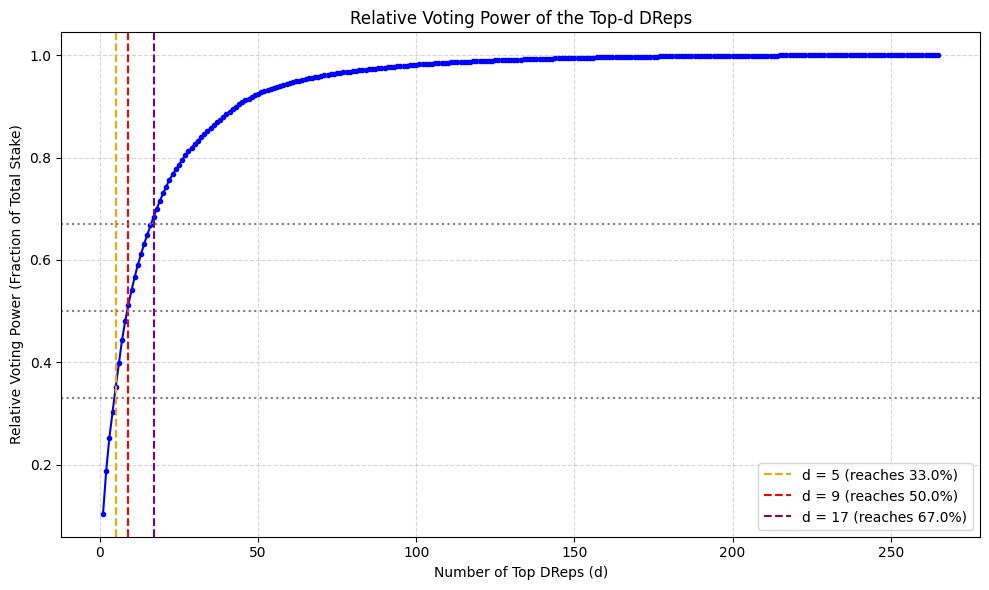

In [ ]:
# @title Cumulative Voting Power and Various Thresholds <br> <h5> Set three threshold values to see the minimum number of DReps required to pass this threshold (e.g., 1/3, 1/2, 2/3)</h5> { run: "auto" }
threshold_1 = 0.33 # @param {type:"slider", min:0.05, max:1.0, step:0.01}
threshold_2 = 0.5 # @param {type:"slider", min:0.05, max:1.0, step:0.01}
threshold_3 = 0.67 # @param {type:"slider", min:0.05, max:1.0, step:0.01}

import csv
import matplotlib.pyplot as plt

# Read DReps and their stakes from dreps.csv
dreps = []
with open("dreps.csv", "r", encoding="utf-8") as f:
    reader = csv.reader(f)
    for row in reader:
        if len(row) == 2:
            drep_id = row[0]
            stake = float(row[1])
            dreps.append((drep_id, stake))

# Sort DReps by stake in descending order
dreps_sorted = sorted(dreps, key=lambda x: x[1], reverse=True)
total_active_stake = sum(stake for _, stake in dreps_sorted)

# Compute cumulative relative voting power
x_values = list(range(1, len(dreps_sorted) + 1))
cumulative_relative_stake = []
current_sum = 0.0

d_t1 = None
d_t2 = None
d_t3 = None

for i, (_, stake) in enumerate(dreps_sorted, start=1):
    current_sum += stake
    relative_power = current_sum / total_active_stake
    cumulative_relative_stake.append(relative_power)

    if d_t1 is None and relative_power >= threshold_1:
        d_t1 = i
    if d_t2 is None and relative_power >= threshold_2:
        d_t2 = i
    if d_t3 is None and relative_power >= threshold_3:
        d_t3 = i

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(x_values, cumulative_relative_stake, marker='o', markersize=3, linestyle='-', color='b')

# Add threshold line 1
if d_t1 is not None:
    plt.axvline(x=d_t1, color='orange', linestyle='--', label=f'd = {d_t1} (reaches {threshold_1*100:.1f}%)')
    plt.axhline(y=threshold_1, color='gray', linestyle=':')
    print(f"The top {d_t1} DReps hold at least {threshold_1*100:.1f}% of the total voting power.")

# Add threshold line 2
if d_t2 is not None:
    plt.axvline(x=d_t2, color='r', linestyle='--', label=f'd = {d_t2} (reaches {threshold_2*100:.1f}%)')
    plt.axhline(y=threshold_2, color='gray', linestyle=':')
    print(f"The top {d_t2} DReps hold at least {threshold_2*100:.1f}% of the total voting power.")

# Add threshold line 3
if d_t3 is not None:
    plt.axvline(x=d_t3, color='purple', linestyle='--', label=f'd = {d_t3} (reaches {threshold_3*100:.1f}%)')
    plt.axhline(y=threshold_3, color='gray', linestyle=':')
    print(f"The top {d_t3} DReps hold at least {threshold_3*100:.1f}% of the total voting power.")

plt.legend()
plt.title("Relative Voting Power of the Top-d DReps")
plt.xlabel("Number of Top DReps (d)")
plt.ylabel("Relative Voting Power (Fraction of Total Stake)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# @title Generate Artificial (Random) DRep Delegation  { run: "auto" }
n = 2000 # @param {type:"integer"}
d = 10 # @param {type:"integer"}
x = 80 # @param {type:"integer"}
noise_distribution = "Gaussian" # @param ["Uniform [0, x]", "Gaussian"]
gaussian_std_dev = 5 # @param {type:"number"}

import numpy as np

# 1. Base delegation: first d DReps have delegation x, rest have 0
base_stake = np.zeros(n)
base_stake[:min(d, n)] = x

# 2. Add noise independently to each entry
if noise_distribution == "Uniform [0, x]":
    noise = np.random.uniform(0, x, n)
elif noise_distribution == "Gaussian":
    noise = np.random.normal(0, gaussian_std_dev, n)
else:
    noise = np.zeros(n)

# 3. Compute final stakes and ensure they are positive (clipped to 0 if negative)
final_stakes = np.clip(base_stake + noise, 0, None)

# Save the results in a vector "stake" (as list of floats)
stake = [float(s) for s in final_stakes]

# Print summary of generated vector
print(f"Generated delegation vector of size n = {n}")
print(f"Active elements with base delegation x = {x}: {min(d, n)}")
print(f"Noise distribution: {noise_distribution}")
print(f"Total generated stake: {sum(stake):,.2f}")
print(f"Top 10 stakes preview: {[f'{s:,.2f}' for s in sorted(stake, reverse=True)[:10]]}")

Generated delegation vector of size n = 2000
Active elements with base delegation x = 80: 10
Noise distribution: Gaussian
Total generated stake: 4,676.92
Top 10 stakes preview: ['86.84', '86.05', '84.97', '83.12', '82.54', '79.86', '79.86', '78.81', '74.10', '73.94']


In [ ]:
import csv
import json
import urllib.request as urllib_req
import plotly.graph_objects as go

# @title Run Mechanism with Select Parameters <h5>Choose: input data source (actual DReps or artificial), parameter d, and desired reward per eligible DRep </h5> { run: "auto" }
data_source = "actual DReps distribution" # @param ["actual DReps distribution", "random/artificial distribution"]
d = 200 # @param {type:"slider", min:10, max:5000, step:10}
desired_reward = 2000 # @param {type:"number"}

# Prepare DReps and stakes based on selected data source
dreps = []
total_stake = 0.0

if data_source == "actual DReps distribution":
    try:
        with open("dreps.csv", "r", encoding="utf-8") as f:
            reader = csv.reader(f)
            for row in reader:
                if len(row) == 2:
                    drep_id = row[0]
                    stake_val = float(row[1])
                    dreps.append((drep_id, stake_val))
                    total_stake += stake_val
    except FileNotFoundError:
        print("dreps.csv not found locally. Attempting to fetch live data from Koios API...")
        try:
            req_list = urllib_req.Request(
                "https://api.koios.rest/api/v1/drep_list?registered=eq.true&select=drep_id",
                headers={"accept": "application/json"}
            )
            with urllib_req.urlopen(req_list, timeout=60) as response:
                ids = [d["drep_id"] for d in json.loads(response.read().decode())]

            info_rows = []
            for i in range(0, len(ids), 50):
                chunk_ids = ids[i:i + 50]
                req_info = urllib_req.Request(
                    "https://api.koios.rest/api/v1/drep_info",
                    data=json.dumps({"_drep_ids": chunk_ids}).encode(),
                    headers={"accept": "application/json", "content-type": "application/json"}
                )
                with urllib_req.urlopen(req_info, timeout=60) as response:
                    info_rows += json.loads(response.read().decode())

            for r in info_rows:
                if r.get("active") is not False and int(r.get("amount", 0)) > 0:
                    drep_id = r["drep_id"]
                    stake_val = int(r["amount"]) / 1e6
                    dreps.append((drep_id, stake_val))
                    total_stake += stake_val
            print(f"Successfully fetched {len(dreps)} active DReps from Koios API fallback.")
        except Exception as e:
            print(f"API fallback failed: {e}. Please ensure you are connected to the internet.")
else:
    # Use the 'stake' list generated in the previous cell
    if 'stake' in globals() and len(stake) > 0:
        for idx, stake_val in enumerate(stake, start=1):
            drep_id = f"DRep_{idx}"
            dreps.append((drep_id, stake_val))
            total_stake += stake_val
    else:
        print("No random vector 'stake' found. Please run the previous generation cell first.")

# Sort DReps by stake in descending order
dreps_sorted = sorted(dreps, key=lambda x: x[1], reverse=True)

# Calculate the threshold (1/d of total stake)
threshold = total_stake / d if d > 0 else 0.0

# Separate those passing the threshold from those that do not
passing_dreps = [(drep_id, s) for drep_id, s in dreps_sorted if s >= threshold]
n_passing = len(passing_dreps)

# Calculate threshold percentage relative to total voting power
threshold_percentage = (1 / d) * 100 if d > 0 else 0.0

# Calculate budgets
required_budget = desired_reward * d
consumed_budget = desired_reward * n_passing
budget_percentage = (consumed_budget / required_budget) * 100 if required_budget > 0 else 0.0

not_passing_dreps = [(drep_id, s) for drep_id, s in dreps_sorted if s < threshold]

# Extract x-values, stakes, labels and calculate percentages for passing DReps
x_passing = list(range(1, n_passing + 1))
y_passing = [s for _, s in passing_dreps]

labels_passing = [drep_id for drep_id, _ in passing_dreps]
pct_passing = [(s / total_stake) * 100 if total_stake > 0 else 0.0 for _, s in passing_dreps]

# Take up to 10 additional DReps that did not pass
additional_dreps = not_passing_dreps[:10]

x_additional = list(range(n_passing + 1, n_passing + len(additional_dreps) + 1))
y_additional = [s for _, s in additional_dreps]
labels_additional = [drep_id for drep_id, _ in additional_dreps]
pct_additional = [(s / total_stake) * 100 if total_stake > 0 else 0.0 for _, s in additional_dreps]

# Create interactive Plotly figure
fig = go.Figure()

# Plot the passing DReps in green
if x_passing:
    fig.add_trace(go.Scatter(
        x=x_passing,
        y=y_passing,
        mode='lines+markers',
        name='Passing Threshold',
        marker=dict(size=6, color='green'),
        line=dict(color='green'),
        text=labels_passing,
        customdata=pct_passing,
        hovertemplate='<b>DRep:</b> %{text}<br><b>Rank/Index:</b> %{x}<br><b>Voting Power:</b><br>%{y:,.2f} ADA<br>(%{customdata:.2f}%)<extra></extra>'
    ))

# Plot the non-passing DReps in red
if x_additional:
    fig.add_trace(go.Scatter(
        x=x_additional,
        y=y_additional,
        mode='lines+markers',
        name='Below Threshold (Next 10)',
        marker=dict(size=6, color='red'),
        line=dict(color='red'),
        text=labels_additional,
        customdata=pct_additional,
        hovertemplate='<b>DRep:</b> %{text}<br><b>Rank/Index:</b> %{x}<br><b>Voting Power:</b><br>%{y:,.2f} ADA<br>(%{customdata:.2f}%)<extra></extra>'
    ))

    # Add a separate, marker-less line to visually bridge the transition from green to red
    if x_passing:
        fig.add_trace(go.Scatter(
            x=[x_passing[-1], x_additional[0]],
            y=[y_passing[-1], y_additional[0]],
            mode='lines',
            line=dict(color='red', dash='dot'),
            showlegend=False,
            hoverinfo='skip'
        ))

# Add visual line for the threshold itself
fig.add_shape(
    type="line",
    x0=1,
    y0=threshold,
    x1=max(x_passing + x_additional) if (x_passing or x_additional) else 1,
    y1=threshold,
    line=dict(color="orange", width=2, dash="dash"),
    name="Threshold Line"
)

# Add annotation/text box to print budget details directly on the plot
annotation_text = (
    f"<b>Budget Metrics:</b><br>"
    f"Required budget (B): {required_budget:,.2f} ADA<br>"
    f"Consumed budget (B_used): {consumed_budget:,.2f} ADA ({budget_percentage:.2f}%)"
)

fig.add_annotation(
    xref="paper", yref="paper",
    x=0.95, y=0.95,
    text=annotation_text,
    showarrow=False,
    font=dict(size=12, color="black"),
    align="left",
    bgcolor="rgba(255, 255, 255, 0.8)",
    bordercolor="gray",
    borderwidth=1
)

fig.update_layout(
    title=f'Individual Voting Power of DReps Passing vs Below 1/{d} Threshold ({threshold_percentage:.2g}% voting power needed)',
    xaxis_title='Number of DReps',
    yaxis_title='Voting Power (ADA)',
    template='plotly_white',
    hovermode='closest',
    width=1000,
    height=600,
    showlegend=True
)

fig.show()

In [ ]:
import csv
import plotly.graph_objects as go
import numpy as np

# @title Budget Scenario Selector { run: "auto" }
data_source = "actual DReps distribution" # @param ["actual DReps distribution", "random/artificial distribution"]
desired_reward = 1000 # @param {type:"number"}

# Read DReps and their stakes based on the chosen data source
dreps = []
total_stake = 0.0

if data_source == "actual DReps distribution":
    try:
        with open("dreps.csv", "r", encoding="utf-8") as f:
            reader = csv.reader(f)
            for row in reader:
                if len(row) == 2:
                    drep_id = row[0]
                    stake_val = float(row[1])
                    dreps.append((drep_id, stake_val))
                    total_stake += stake_val
    except FileNotFoundError:
        # Fallback if file not found
        if 'baseline_dreps' in globals():
            dreps = baseline_dreps
            total_stake = sum(s for _, s in baseline_dreps)
        else:
            dreps = [("DRep_Fallback", 5153185583.72)]
            total_stake = 5153185583.72
else:
    # Explicitly prioritize the 'stake' list generated in the DRep Delegation cell
    if 'stake' in globals() and len(stake) > 0:
        for idx, stake_val in enumerate(stake, start=1):
            dreps.append((f"DRep_{idx}", stake_val))
            total_stake += stake_val
    elif 'selected_distribution' in globals() and len(selected_distribution) > 0:
        dreps = selected_distribution
        total_stake = sum(s for _, s in selected_distribution)
    else:
        if 'baseline_dreps' in globals():
            dreps = baseline_dreps
            total_stake = sum(s for _, s in baseline_dreps)

# Sort DReps by stake in descending order
dreps_sorted = sorted(dreps, key=lambda x: x[1], reverse=True)
stakes = np.array([stake_val for _, stake_val in dreps_sorted])

# We will calculate the consumed budget for a range of d values
d_values = list(range(10, 5010, 10))
consumed_budgets = []
passing_counts = []

for d_val in d_values:
    threshold_val = total_stake / d_val if d_val > 0 else 0.0
    # Count how many DReps pass the threshold
    n_passing_val = np.sum(stakes >= threshold_val)
    passing_counts.append(int(n_passing_val))
    consumed_budgets.append(desired_reward * n_passing_val)

# Create interactive Plotly figure
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=d_values,
    y=consumed_budgets,
    mode='lines',
    line=dict(color='blue', width=2),
    name='Consumed Budget',
    customdata=passing_counts,
    hovertemplate='<b>d:</b> %{x}<br><b>Passing DReps:</b> %{customdata}<br><b>Consumed Budget:</b> %{y:,.2f} ADA<extra></extra>'
))

fig.update_layout(
    title=f'Consumed Budget vs Parameter d (for Desired Reward = {desired_reward:,.2f} ADA)',
    xaxis_title='Parameter d (1/d Threshold Factor)',
    yaxis_title='Consumed Budget (ADA)',
    template='plotly_white',
    width=1000,
    height=600
)

fig.show()

# Simulations

## <span style="color:red">**Self-enrichment** - What if DReps vote for changing $d$?</span>


### Incentives to Change d: Worst-Case / Pessimistic Reward-Optimization Scenario

Consider the scenario where DReps vote for changing the mechanism parameter $d$. To analyze how incentives might affect the mechanism parameter decentralization, we consider a pessimistic scenario in which DReps only care about their own reward:

1. **Voting on Parameter $d$**: DReps directly vote on lowering the decentralization parameter $d$ of the mechanism (which acts to loosen the threshold needed to qualify for rewards, but increases individual reward payouts).
2. **Worst-Case  Financial Incentive**: If reducing the current parameter $d$ to a smaller parameter $d'$ still allows a DRep to remain included, its individual reward $\frac{B}{d'}$ increases. DReps who only care about their own reward (ignoring other important aspects like system decentralization, possibility of loosing part of their delegation, etc.) would vote in favor of such smaller $d'$.
3. **Myopic Ideal Parameter ($d_r$)**: Each DRep with rank $r$ can compute their own ideal parameter boundary, $d_r$, which is the minimum parameter such that their relative voting power is still above $\frac{1}{d_r}$. The ratio $\frac{d}{d_r}$ represents the best possible multiplier of reward improvement. It reflects how suboptimal the current $d$ is perceived by that individual DRep if they disregard any external variables (e.g., losing delegation,  or system decentralization).
4. **Pessimistic Sequential Dynamics**: For any proposed threshold reduction, a $2/3$ majority of total network voting power is required to pass the vote. In this pessimistic model, we simulate repeated voting rounds where all DReps act strictly as selfish agents trying to optimize their own payout. They ignore the negative impact of higher concentration of rewards or degraded decentralization on the wider ecosystem.

In [ ]:
# @title Minimum $d / d_r$ Ratio for Included DReps <br><h5>Maximum each DRep could improve changing d given its current rank r</h5> { run: "auto" }
data_source = "actual DReps distribution" # @param ["actual DReps distribution", "random/artificial distribution"]
d = 100 # @param {type:"slider", min:10, max:5000, step:10}
gain_threshold = 1e-9 # @param {type:"slider", min:1e-9, max:1e-7, step:1e-9}
risk_sensitiveness = 0 # @param {type:"slider", min:0.0, max:1.0, step:0.05}

import csv
import math
import urllib.request as urllib_req
import json
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

# Prepare DReps and stakes based on selected data source
dreps = []
total_stake = 0.0

if data_source == "actual DReps distribution":
    try:
        with open("dreps.csv", "r", encoding="utf-8") as f:
            reader = csv.reader(f)
            for row in reader:
                if len(row) == 2:
                    drep_id = row[0]
                    stake_val = float(row[1])
                    dreps.append((drep_id, stake_val))
                    total_stake += stake_val
    except FileNotFoundError:
        print("dreps.csv not found locally. Attempting to fetch live data from Koios API...")
        try:
            req_list = urllib_req.Request(
                "https://api.koios.rest/api/v1/drep_list?registered=eq.true&select=drep_id",
                headers={"accept": "application/json"}
            )
            with urllib_req.urlopen(req_list, timeout=60) as response:
                ids = [d["drep_id"] for d in json.loads(response.read().decode())]

            info_rows = []
            for i in range(0, len(ids), 50):
                chunk_ids = ids[i:i + 50]
                req_info = urllib_req.Request(
                    "https://api.koios.rest/api/v1/drep_info",
                    data=json.dumps({"_drep_ids": chunk_ids}).encode(),
                    headers={"accept": "application/json", "content-type": "application/json"}
                )
                with urllib_req.urlopen(req_info, timeout=60) as response:
                    info_rows += json.loads(response.read().decode())

            for r in info_rows:
                if r.get("active") is not False and int(r.get("amount", 0)) > 0:
                    drep_id = r["drep_id"]
                    stake_val = int(r["amount"]) / 1e6
                    dreps.append((drep_id, stake_val))
                    total_stake += stake_val
            print(f"Successfully fetched {len(dreps)} active DReps from Koios API fallback.")
        except Exception as e:
            print(f"API fallback failed: {e}. Please ensure you are connected to the internet.")
else:
    # Explicitly prioritize the 'stake' list generated in the DRep Delegation cell
    if 'stake' in globals() and len(stake) > 0:
        for idx, stake_val in enumerate(stake, start=1):
            drep_id = f"DRep_{idx}"
            dreps.append((drep_id, stake_val))
            total_stake += stake_val
    elif 'selected_distribution' in globals() and len(selected_distribution) > 0:
        dreps = selected_distribution
        total_stake = sum(s for _, s in selected_distribution)
    else:
        if 'baseline_dreps' in globals():
            dreps = baseline_dreps
            total_stake = sum(s for _, s in baseline_dreps)

# Sort DReps by stake in descending order
dreps_sorted = sorted(dreps, key=lambda x: x[1], reverse=True)

# Find the rank r where cumulative voting power reaches at least 2/3 (67%)
cumulative_sum = 0.0
rank_2_3 = None
for idx, (_, stake_val) in enumerate(dreps_sorted, start=1):
    cumulative_sum += stake_val
    if cumulative_sum >= (2.0 / 3.0) * total_stake:
        rank_2_3 = idx
        break

# Filter DReps passing the threshold (stake >= total_stake / d)
threshold = total_stake / d if d > 0 else 0.0
passing_dreps = [(rank, drep_id, stake_val) for rank, (drep_id, stake_val) in enumerate(dreps_sorted, start=1) if stake_val >= threshold]

if not passing_dreps:
    print(f"No DReps pass the threshold for d = {d}")
else:
    ranks = [r[0] for r in passing_dreps]
    labels = [r[1] for r in passing_dreps]
    stakes_val = [r[2] for r in passing_dreps]
    pct_val = [(stake_val / total_stake) * 100 if total_stake > 0 else 0.0 for stake_val in stakes_val]

    # d_r is the minimum positive integer parameter such that stake >= total_stake / d_r
    d_r_values = [math.ceil(total_stake / stake_val) if stake_val > 0 else float('inf') for stake_val in stakes_val]
    ratios = [d / d_r if d_r > 0 else 0.0 for d_r in d_r_values]

    # Calculate relative improvement: (d / d_r) / voting_power
    rel_improvements = [ratio / stake_val if stake_val > 0 else 0.0 for ratio, stake_val in zip(ratios, stakes_val)]

    # Color points based on whether relative improvement exceeds gain_threshold
    colors = ['red' if imp > gain_threshold else 'royalblue' for imp in rel_improvements]

    # Create Subplots: 2 rows, 1 column, sharing x-axis
    fig = make_subplots(
        rows=2, cols=1,
        shared_xaxes=True,
        vertical_spacing=0.08,
        subplot_titles=(
            f"Ratio of Selected d ({d}) to Minimum d_r for Included DReps (d / d_r)",
            "Relative Improvement ratio: (d / d_r) / Voting Power"
        )
    )

    # Row 1: d/d_r Ratio Plot
    fig.add_trace(go.Scatter(
        x=ranks,
        y=ratios,
        mode='lines+markers',
        marker=dict(size=8, color=colors, line=dict(width=1, color='DarkSlateGrey')),
        line=dict(color='royalblue', width=2),
        text=labels,
        customdata=np.stack((stakes_val, pct_val, d_r_values, rel_improvements), axis=-1),
        hovertemplate='<b>Rank:</b> %{x}<br><b>DRep:</b> %{text}<br><b>Voting Power:</b> %{customdata[0]:,.2f} ADA (%{customdata[1]:.2f}%)<br><b>Min d_r required:</b> %{customdata[2]}<br><b>Ratio d/d_r:</b> %{y:.4f}<br><b>Relative Improvement:</b> %{customdata[3]:.4e}<extra></extra>'
    ), row=1, col=1)

    # Row 2: Relative Improvement Plot
    fig.add_trace(go.Scatter(
        x=ranks,
        y=rel_improvements,
        mode='lines+markers',
        marker=dict(size=8, color=colors, line=dict(width=1, color='DarkSlateGrey')),
        line=dict(color='firebrick', width=2),
        text=labels,
        customdata=np.stack((stakes_val, pct_val, d_r_values, ratios), axis=-1),
        hovertemplate='<b>Rank:</b> %{x}<br><b>DRep:</b> %{text}<br><b>Voting Power:</b> %{customdata[0]:,.2f} ADA (%{customdata[1]:.2f}%)<br><b>Min d_r required:</b> %{customdata[2]}<br><b>Ratio d/d_r:</b> %{customdata[3]:.4f}<br><b>Relative Improvement:</b> %{customdata[3]:.4e}<extra></extra>'
    ), row=2, col=1)

    # Draw vertical line for 2/3 cumulative power rank on both subplots
    if rank_2_3 is not None:
        fig.add_vline(
            x=rank_2_3,
            line_width=2,
            line_dash="dash",
            line_color="purple",
            annotation_text=f"2/3 Voting Power (Rank {rank_2_3})",
            annotation_position="top right"
        )

    fig.update_layout(
        xaxis2_title='DRep Rank (r)',
        yaxis_title='Ratio (d / d_r)',
        yaxis2_title='Relative Improvement',
        yaxis=dict(tickformat='.2%'),
        yaxis2=dict(tickformat='.2e'),
        template='plotly_white',
        width=1000,
        height=900,
        showlegend=False
    )

    fig.show()

In [ ]:
# @title DRep d-Reduction Voting Dynamics Simulation { run: "auto" }

import csv
import math

# Read DReps and their stakes from dreps.csv
dreps = []
total_stake = 0.0
with open("dreps.csv", "r", encoding="utf-8") as f:
    reader = csv.reader(f)
    for row in reader:
        if len(row) == 2:
            drep_id = row[0]
            stake = float(row[1])
            dreps.append((drep_id, stake))
            total_stake += stake

# Sort DReps by stake in descending order
dreps_sorted = sorted(dreps, key=lambda x: x[1], reverse=True)

# Simulation settings from preceding sliders or local default
current_d = d  # Uses 'd' variable from the preceding cell

print(f"Starting simulation with initial d = {current_d}")
print(f"Total network voting power: {total_stake:,.2f} ADA")
print(f"Required 2/3 majority voting power: {(2/3)*total_stake:,.2f} ADA\n")

steps = 0
while current_d > 1:
    # Candidate next d
    next_d = current_d - 1

    yes_votes_stake = 0.0
    yes_voters_count = 0

    # Evaluate votes for each DRep
    for rank, (drep_id, stake) in enumerate(dreps_sorted, start=1):
        # 1. Check if the DRep is included under CURRENT d
        current_threshold = total_stake / current_d
        if stake < current_threshold:
            # For DReps not included with current d, the vote is always No
            continue

        # 2. Compute minimum d_r needed for this DRep to be included
        d_r = math.ceil(total_stake / stake)

        # 3. Compute relative improvement metrics
        # Relative Improvement = (d / d_r) / voting_power
        current_ratio = current_d / d_r
        current_improvement = current_ratio / stake

        # In order for lowering the threshold to be desirable for included DReps,
        # we define their improvement ratio as current_d / next_d (greater than 1)
        # since it reduces the competition threshold, or evaluate the vote based on their rank status.
        improvement_ratio = current_d / next_d

        if improvement_ratio > 1.0:
            yes_votes_stake += stake
            yes_voters_count += 1

    # Check if Yes votes reach at least 2/3 of total network stake
    if yes_votes_stake >= (2.0 / 3.0) * total_stake:
        print(f"[Step {steps+1}] d = {current_d} -> {next_d} | Yes Votes: {yes_votes_stake:,.2f} ADA ({ (yes_votes_stake/total_stake)*100 :.2f}%) from {yes_voters_count} DReps. PASSED.")
        current_d = next_d
        steps += 1
    else:
        print(f"[Stop] d = {current_d} | Yes Votes: {yes_votes_stake:,.2f} ADA ({ (yes_votes_stake/total_stake)*100 :.2f}%) from {yes_voters_count} DReps. FAILED to reach 2/3 majority.")
        break

print(f"\nSimulation finished. Final d: {current_d} (Reduced {steps} times)")

Starting simulation with initial d = 100
Total network voting power: 4,638,395,775.03 ADA
Required 2/3 majority voting power: 3,092,263,850.02 ADA

[Step 1] d = 100 -> 99 | Yes Votes: 3,559,260,839.12 ADA (76.73%) from 23 DReps. PASSED.
[Step 2] d = 99 -> 98 | Yes Votes: 3,559,260,839.12 ADA (76.73%) from 23 DReps. PASSED.
[Step 3] d = 98 -> 97 | Yes Votes: 3,559,260,839.12 ADA (76.73%) from 23 DReps. PASSED.
[Step 4] d = 97 -> 96 | Yes Votes: 3,559,260,839.12 ADA (76.73%) from 23 DReps. PASSED.
[Step 5] d = 96 -> 95 | Yes Votes: 3,559,260,839.12 ADA (76.73%) from 23 DReps. PASSED.
[Step 6] d = 95 -> 94 | Yes Votes: 3,559,260,839.12 ADA (76.73%) from 23 DReps. PASSED.
[Step 7] d = 94 -> 93 | Yes Votes: 3,510,422,836.65 ADA (75.68%) from 22 DReps. PASSED.
[Step 8] d = 93 -> 92 | Yes Votes: 3,510,422,836.65 ADA (75.68%) from 22 DReps. PASSED.
[Step 9] d = 92 -> 91 | Yes Votes: 3,510,422,836.65 ADA (75.68%) from 22 DReps. PASSED.
[Step 10] d = 91 -> 90 | Yes Votes: 3,510,422,836.65 ADA (7

In [ ]:
# @title **Dynamics 1:** DReps Vote for Reducing $d$  <h5> Starting from some initial d, at each round DReps vote to reduce it by some amout l. A parameter `risk sensitiveness' represents the (perceived) risk of loosing its own delegation when voting in favor of this more centralized / reduced d. <br> After choosing the parameters, click on play below to vizualize the dynamics step by step (when a lower d is passed, typically some DReps desappear from the currently reward eligible DReps). <br> All DReps still participate in the voting, and DReps not eligible for rewards vote against lowering parameter d. </h5>{ run: "auto" }
initial_d = 100 # @param {type:"slider", min:10, max:2000, step:10}
l = 1 # @param {type:"slider", min:1, max:50, step:1}
risk_sensitiveness = 0.01 # @param {type:"slider", min:0.0, max:0.1, step:0.005}

import csv
import math
import plotly.graph_objects as go
import json
import urllib.request as urllib_req
import numpy as np

# 1. Read and Sort DReps with API fallback
dreps = []
total_stake = 0.0
try:
    with open("dreps.csv", "r", encoding="utf-8") as f:
        reader = csv.reader(f)
        for row in reader:
            if len(row) == 2:
                drep_id = row[0]
                stake = float(row[1])
                dreps.append((drep_id, stake))
                total_stake += stake
except FileNotFoundError:
    try:
        print("dreps.csv not found. Fetching live data from Koios API for simulation...")
        req_list = urllib_req.Request(
            "https://api.koios.rest/api/v1/drep_list?registered=eq.true&select=drep_id",
            headers={"accept": "application/json"}
        )
        with urllib_req.urlopen(req_list, timeout=60) as response:
            ids = [d["drep_id"] for d in json.loads(response.read().decode())]

        info_rows = []
        for i in range(0, len(ids), 50):
            chunk_ids = ids[i:i + 50]
            req_info = urllib_req.Request(
                "https://api.koios.rest/api/v1/drep_info",
                data=json.dumps({"_drep_ids": chunk_ids}).encode(),
                headers={"accept": "application/json", "content-type": "application/json"}
            )
            with urllib_req.urlopen(req_info, timeout=60) as response:
                info_rows += json.loads(response.read().decode())

        for r in info_rows:
            if r.get("active") is not False and int(r.get("amount", 0)) > 0:
                drep_id = r["drep_id"]
                stake = int(r["amount"]) / 1e6
                dreps.append((drep_id, stake))
                total_stake += stake
    except Exception as e:
        print(f"API fallback failed: {e}. Please run the download cells above first.")

dreps_sorted = sorted(dreps, key=lambda x: x[1], reverse=True)

# 2. Run simulation and record history
current_d = initial_d
history = []
steps = 0

while current_d > l:
    next_d = current_d - l
    yes_votes_stake = 0.0
    included_current = []

    current_threshold = total_stake / current_d
    next_threshold = total_stake / next_d

    # Evaluate current state and collect votes for reduction based on risk sensitiveness
    for rank, (drep_id, stake) in enumerate(dreps_sorted, start=1):
        if stake >= current_threshold:
            included_current.append((drep_id, stake, rank))

            # If they are still included, evaluate the custom voting condition:
            # Reward Gain vs. Risk Penalty:
            # R * (1/d' - 1/d) - risk_sensitiveness * delegation > 0
            # Where R is the budget/reputation multiplier. We use the normalized reward change multiplier.
            if stake >= next_threshold:
                reward_gain = (1.0 / next_d) - (1.0 / current_d)
                penalty = risk_sensitiveness * (stake / 1e6)  # Scale absolute ADA to millions for numerical balance
                if reward_gain - penalty > 0:
                    yes_votes_stake += stake

    # Record history step
    history.append({
        'd': current_d,
        'included': included_current,
        'yes_votes_pct': (yes_votes_stake / total_stake) * 100
    })

    # Check for 2/3 majority requirement to proceed to next_d
    if yes_votes_stake >= (2.0 / 3.0) * total_stake:
        current_d = next_d
        steps += 1
    else:
        break

# If we stopped, append the final terminal state evaluation
if current_d > 0:
    final_included = []
    final_threshold = total_stake / current_d
    for rank, (drep_id, stake) in enumerate(dreps_sorted, start=1):
        if stake >= final_threshold:
            final_included.append((drep_id, stake, rank))
    history.append({
        'd': current_d,
        'included': final_included,
        'yes_votes_pct': 0.0
    })

# 3. Build Plotly Animation
fig = go.Figure()

init_step = history[0]
init_labels = [item[0] for item in init_step['included']]
init_stakes = [item[1] for item in init_step['included']]
init_pcounts = [(item[1] / total_stake) * 100 for item in init_step['included']]
init_texts = [f"{stake:,.0f} ({pct:.2f}%)" for stake, pct in zip(init_stakes, init_pcounts)]

fig.add_trace(go.Bar(
    x=init_labels,
    y=init_stakes,
    marker=dict(color='royalblue'),
    name='DRep Voting Power',
    customdata=init_pcounts,
    text=init_texts,
    textposition='auto',
    hovertemplate='<b>DRep:</b> %{x}<br><b>Voting Power:</b> %{y:,.2f} ADA (%{customdata:.2f}%)<extra></extra>'
))

# Create animation frames
frames = []
for h_step in history:
    f_labels = [item[0] for item in h_step['included']]
    f_stakes = [item[1] for item in h_step['included']]
    f_pcounts = [(item[1] / total_stake) * 100 for item in h_step['included']]
    f_texts = [f"{stake:,.0f} ({pct:.2f}%)" for stake, pct in zip(f_stakes, f_pcounts)]
    frames.append(go.Frame(
        data=[go.Bar(
            x=f_labels,
            y=f_stakes,
            customdata=f_pcounts,
            text=f_texts,
            textposition='auto',
            hovertemplate='<b>DRep:</b> %{x}<br><b>Voting Power:</b> %{y:,.2f} ADA (%{customdata:.2f}%)<extra></extra>'
        )],
        name=str(h_step['d']),
        layout=go.Layout(
            title_text=f"DRep Voting Power Distribution | d = {h_step['d']} (Yes Votes to reduce: {h_step['yes_votes_pct']:.2f}%)"
        )
    ))

fig.frames = frames

fig.update_layout(
    title=f"DRep Voting Power Distribution | d = {init_step['d']} (Yes Votes: {init_step['yes_votes_pct']:.2f}%)",
    xaxis_title="Included DReps",
    yaxis_title="Voting Power (ADA)",
    template='plotly_white',
    updatemenus=[{
        'type': 'buttons',
        'buttons': [
            {
                'label': 'Play',
                'method': 'animate',
                'args': [None, {
                    'frame': {'duration': 250, 'redraw': True},
                    'fromcurrent': True,
                    'transition': {'duration': 150}
                }]
            },
            {
                'label': 'Pause',
                'method': 'animate',
                'args': [[None], {
                    'frame': {'duration': 0, 'redraw': True},
                    'mode': 'immediate',
                    'transition': {'duration': 0}
                }]
            }
        ],
        'direction': 'left',
        'pad': {'r': 10, 't': 87},
        'showactive': False,
        'x': 0.1,
        'xanchor': 'right',
        'y': 0,
        'yanchor': 'top'
    }],
    width=1000,
    height=600
)

fig.show()

In [ ]:
# @title **Dynamics 2:** Delegation Moves across DReps & Reward Eligibility Changes { run: "auto" }
# @markdown ### How to use this simulation:
# @markdown This simulation models a dynamic scenario where ADA holders move their delegation among DReps over sequential rounds ($T$). At each round, some fraction of delegation moves from a DRep to another DRep (the latter chosen proportionally to current relative delegation).
# @markdown
# @markdown **Parameters:**
# @markdown - **`T`** (Total Rounds): The total duration of the simulation. More rounds allow the delegation distribution to drift further from its initial state.
# @markdown - **`fraction`**: The proportion of delegation moved from a selected source DRep to a target DRep during a redistribution step.
# @markdown - **`d`**: The decentralization parameter. It establishes the reward-eligibility threshold as $1/d$ of the total active stake. Only DReps meeting or exceeding this threshold qualify for rewards.
# @markdown
# @markdown The playback animation displays the evolving distribution of reward-eligible DReps, while the static chart below tracks the total eligible count over time.

T = 30 # @param {type:"slider", min:10, max:500, step:10}
fraction = 0.2 # @param {type:"slider", min:0.01, max:0.5, step:0.01}
d = 100 # @param {type:"slider", min:10, max:1000, step:10}

import csv
import random
import numpy as np
import plotly.graph_objects as go
import matplotlib.pyplot as plt

# 1. Load initial distribution
dreps = []
total_stake = 0.0
try:
    with open("dreps.csv", "r", encoding="utf-8") as f:
        reader = csv.reader(f)
        for row in reader:
            if len(row) == 2:
                drep_id = row[0]
                stake = float(row[1])
                dreps.append((drep_id, stake))
                total_stake += stake
except FileNotFoundError:
    # Fallback if baseline doesn't exist
    baseline_total = 5153185583.73
    dreps = [(f"DRep_{i}", baseline_total/100) for i in range(100)]
    total_stake = baseline_total

# Keep track of simulation history for animation
history = []
eligible_counts_history = []
rounds_axis = []

# Simulation loop running exactly T rounds
for t in range(T):
    # Re-calculate probabilities proportional to delegation
    stakes_array = np.array([d_item[1] for d_item in dreps])
    sum_stakes = np.sum(stakes_array)
    if sum_stakes <= 0:
        break
    probs = stakes_array / sum_stakes

    # Pick two distinct DReps a and b
    idx_a, idx_b = np.random.choice(len(dreps), size=2, replace=False, p=probs)

    # Move a fraction of delegation from a to b
    moved_amount = dreps[idx_a][1] * fraction
    dreps[idx_a] = (dreps[idx_a][0], dreps[idx_a][1] - moved_amount)
    dreps[idx_b] = (dreps[idx_b][0], dreps[idx_b][1] + moved_amount)

    # Determine eligibility for this step
    threshold = sum_stakes / d

    # Sort all DReps to display them side by side
    sorted_dreps = sorted(dreps, key=lambda x: x[1], reverse=True)

    # Count eligible DReps
    n_eligible = sum(1 for item in sorted_dreps if item[1] >= threshold)
    eligible_counts_history.append(n_eligible)
    rounds_axis.append(t + 1)

    history.append({
        'round': t + 1,
        'dreps': sorted_dreps,
        'eligible_count': n_eligible,
        'total_stake': sum_stakes,
        'threshold': threshold
    })

# Build Plotly Animation matching the blue styling
fig = go.Figure()

init_step = history[0]
init_labels = [item[0] for item in init_step['dreps']]
init_stakes = [item[1] for item in init_step['dreps']]
init_pcounts = [(item[1] / init_step['total_stake']) * 100 for item in init_step['dreps']]
init_colors = ['green' if stake >= init_step['threshold'] else 'red' for stake in init_stakes]
init_texts = [f"{stake:,.0f} ({pct:.2f}%)" for stake, pct in zip(init_stakes, init_pcounts)]
init_count = init_step['eligible_count']

fig.add_trace(go.Bar(
    x=init_labels,
    y=init_stakes,
    marker=dict(color=init_colors),
    name='DRep Voting Power',
    customdata=init_pcounts,
    text=init_texts,
    textposition='auto',
    hovertemplate='<b>DRep:</b> %{x}<br><b>Voting Power:</b> %{y:,.2f} ADA (%{customdata:.2f}%)<extra></extra>'
))

frames = []
for h_step in history:
    f_labels = [item[0] for item in h_step['dreps']]
    f_stakes = [item[1] for item in h_step['dreps']]
    f_pcounts = [(item[1] / h_step['total_stake']) * 100 for item in h_step['dreps']]
    f_colors = ['green' if stake >= h_step['threshold'] else 'red' for stake in f_stakes]
    f_texts = [f"{stake:,.0f} ({pct:.2f}%)" for stake, pct in zip(f_stakes, f_pcounts)]
    f_count = h_step['eligible_count']

    frames.append(go.Frame(
        data=[go.Bar(
            x=f_labels,
            y=f_stakes,
            marker=dict(color=f_colors),
            customdata=f_pcounts,
            text=f_texts,
            textposition='auto',
            hovertemplate='<b>DRep:</b> %{x}<br><b>Voting Power:</b> %{y:,.2f} ADA (%{customdata:.2f}%)<extra></extra>'
        )],
        name=str(h_step['round']),
        layout=go.Layout(
            title_text=f"DRep Voting Power & Eligibility | Round {h_step['round']} of {T} | threshold = {h_step['threshold']:,.0f} ADA",
            xaxis=dict(title=f"{f_count} Eligible DReps (Green) | {len(f_stakes) - f_count} Ineligible (Red)")
        )
    ))

fig.frames = frames

fig.update_layout(
    title=f"DRep Voting Power & Eligibility | Round 1 of {T} | threshold = {total_stake/d:,.0f} ADA",
    xaxis_title=f"{init_count} Eligible DReps (Green) | {len(init_stakes) - init_count} Ineligible (Red)",
    yaxis_title="Voting Power (ADA)",
    template='plotly_white',
    updatemenus=[{
        'type': 'buttons',
        'buttons': [
            {
                'label': 'Play',
                'method': 'animate',
                'args': [None, {
                    'frame': {'duration': 200, 'redraw': True},
                    'fromcurrent': True,
                    'transition': {'duration': 100}
                }]
            },
            {
                'label': 'Pause',
                'method': 'animate',
                'args': [[None], {
                    'frame': {'duration': 0, 'redraw': True},
                    'mode': 'immediate',
                    'transition': {'duration': 0}
                }]
            }
        ],
        'direction': 'left',
        'pad': {'r': 10, 't': 87},
        'showactive': False,
        'x': 0.1,
        'xanchor': 'right',
        'y': 0,
        'yanchor': 'top'
    }],
    width=1000,
    height=600
)

fig.show()

# Display the time series graph of the eligible DRep counts
fig_ts = go.Figure()
fig_ts.add_trace(go.Scatter(
    x=rounds_axis,
    y=eligible_counts_history,
    mode='lines',
    line=dict(color='royalblue', width=2),
    name='Eligible DReps'
))
fig_ts.update_layout(
    title="Number of Eligible DReps (above 1/d threshold) Over Rounds",
    xaxis_title="Simulation Round (t)",
    yaxis_title="Count of Included DReps",
    template='plotly_white',
    width=1000,
    height=400
)
fig_ts.show()

In [ ]:
# @title **Dynamics 3:** Strategic DReps &  Best-Response  Dynamics <br> <h5>Choose data source, start with initial value <br> DReps have a linear cost and minimize their own utility (received reward minus cost)</h5>{ run: "auto" }
data_source = "random/artificial distribution" # @param ["actual DReps distribution", "random/artificial distribution"]
num_players = 500 # @param {type:"slider", min:10, max:500, step:10}
initial_V = 100 # @param {type:"number"}
d = 100 # @param {type:"slider", min:5, max:500, step:5}
desired_reward = 200 # @param {type:"number"}
L = 0.043 # @param {type:"slider", min:0.001, max:0.5, step:0.001}
sim_steps = 2280 # @param {type:"slider", min:0, max:20000, step:5}
visualize_distribution = True # @param {type:"boolean"}

import numpy as np
import plotly.graph_objects as go
from IPython.display import clear_output
import time
import csv

# Initialize delegation distribution
if data_source == "actual DReps distribution":
    # Load actual stakes from dreps.csv
    actual_stakes_list = []
    try:
        with open("dreps.csv", "r", encoding="utf-8") as f:
            reader = csv.reader(f)
            for row in reader:
                if len(row) == 2:
                    actual_stakes_list.append(float(row[1]))
    except FileNotFoundError:
        # Fallback if file not found
        if 'baseline_dreps' in globals():
            actual_stakes_list = [s for _, s in baseline_dreps]
        else:
            actual_stakes_list = [50864936.88] * 100
    x = np.array(actual_stakes_list, dtype=float)
    num_players = len(x)
else:
    # Uniform delegation initialization according to inputs
    x = np.full(num_players, float(initial_V))

history_x = []
eligible_counts = []
total_stake_history = []
nakamoto_coefficients = []

# Run sequential best-response dynamics
for step in range(sim_steps):
    # Pick a random DRep
    i = np.random.randint(num_players)

    # Calculate total stake excluding current player's contribution
    sum_others = np.sum(x) - x[i]

    # Exact threshold target derived from: x_i / (x_i + sum_others) = 1/d
    if d > 1:
        if sum_others > 0:
            required_target = sum_others / (d - 1)
        else:
            required_target = 1.0
    else:
        required_target = 0.0

    # Utility from qualifying: reward - L * target
    utility_qualify = desired_reward - (L * required_target)

    # Best response decision
    if utility_qualify >= 0 and required_target >= 0:
        x[i] = required_target
    else:
        x[i] = 0.0

    # Track state
    total_stake = np.sum(x)
    threshold = total_stake / d if d > 0 else 0.0
    active_count = np.sum(x >= threshold)

    history_x.append(x.copy())
    eligible_counts.append(int(active_count))
    total_stake_history.append(float(total_stake))

    # Compute Nakamoto Coefficient
    if total_stake > 0:
        sorted_step = np.sort(x)[::-1]
        cumulative_sum = np.cumsum(sorted_step)
        nakamoto = int(np.argmax(cumulative_sum > 0.5 * total_stake) + 1)
        nakamoto_coefficients.append(nakamoto)
    else:
        nakamoto_coefficients.append(0)

    # Live plotting if checkbox is checked
    if visualize_distribution and (step % max(1, sim_steps // 10) == 0 or step == sim_steps - 1):
        clear_output(wait=True)

        # Create temporary labels and percentages for current DReps
        current_stakes = sorted(x, reverse=True)
        labels = [f"DRep_{idx+1}" for idx in range(num_players)]
        pct_values = [(s / total_stake * 100) if total_stake > 0 else 0.0 for s in current_stakes]
        texts = [f"{s:,.0f} ({p:.2f}%)" for s, p in zip(current_stakes, pct_values)]

        fig_live = go.Figure(data=[go.Bar(
            x=labels,
            y=current_stakes,
            marker=dict(color='royalblue'),
            name='DRep Voting Power',
            customdata=pct_values,
            text=texts,
            textposition='auto',
            hovertemplate='<b>DRep:</b> %{x}<br><b>Voting Power:</b> %{y:,.2f} ADA (%{customdata:.2f}%)<extra></extra>'
        )])

        # Add threshold line
        fig_live.add_shape(
            type="line",
            x0=-0.5,
            y0=threshold,
            x1=num_players-0.5,
            y1=threshold,
            line=dict(color="orange", width=2, dash="dash"),
            name="Threshold Line"
        )

        fig_live.update_layout(
            title=f"Live Distribution Dynamics (Step {step+1}/{sim_steps}) | Eligible: {active_count} | Threshold: {threshold:,.1f} ADA",
            xaxis_title="DReps Sorted by Stake",
            yaxis_title="Voting Power (ADA)",
            template='plotly_white',
            width=1000,
            height=400
        )
        fig_live.show()
        time.sleep(0.05)

# Build Plotly final trend visualizer with Nakamoto Coefficient
fig_dyn = go.Figure()
rounds = list(range(1, sim_steps + 1))

fig_dyn.add_trace(go.Scatter(
    x=rounds,
    y=total_stake_history,
    mode='lines',
    line=dict(color='darkblue', width=2),
    name='Total System Stake'
))

fig_dyn.add_trace(go.Scatter(
    x=rounds,
    y=eligible_counts,
    mode='lines',
    line=dict(color='green', width=2),
    name='Eligible DReps',
    yaxis='y2'
))

fig_dyn.add_trace(go.Scatter(
    x=rounds,
    y=nakamoto_coefficients,
    mode='lines',
    line=dict(color='firebrick', width=2, dash='dot'),
    name='Nakamoto Coefficient',
    yaxis='y2'
))

fig_dyn.update_layout(
    title="DRep Best-Response Strategic Dynamics Over Iterations (Final Trends)",
    xaxis_title="Simulation Step (t)",
    yaxis_title="Total Network Stake (ADA)",
    yaxis2=dict(
        title="Eligible DReps / Nakamoto Coefficient",
        overlaying='y',
        side='right'
    ),
    template='plotly_white',
    width=1000,
    height=550,
    showlegend=True
)
fig_dyn.show()

<h3>Simulation Insights</h3>

**Total System Stake:**  The dark blue line represents the overall stake committed inside the system as players dynamically adjust their targets.

**Eligible DReps:** The green line (plotted on the secondary y-axis) represents the total number of DReps whose individual voting power met or exceeded the threshold.

**Nakamoto Coefficient:** The newly integrated red dash-dotted line tracks the minimum number of DReps who collectively hold more than 50% of the active voting power. This gives a direct, dynamic measure of decentralization over the course of the strategic iterations.

**To do list:**


1.   Add different thresholds corresponding to actual passing criteria (done)
2.   Show the mechanism for the equal/ideal voting distribution (done)
3. Abstain counts (discussion, to do)
4. Put a value on reputation for the dynamics -- simple game variant and effects (done)
5. Extra explanations to make notebook self-contained and easy to understand (partially done)
6. Noisy delegation robustness (including planted models)

